# Objectifs d'apprentissage – Semaine 10

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les différentes structures d'implémentation des filtres RIF et RII.
- **Implémenter** un filtre RIF sous forme directe et en cascade.
- **Implémenter** un filtre RII sous forme directe I, directe II, cascade et parallèle.
- **Analyser** l'influence de la structure sur les performances (stabilité, bruit de calcul).
- **Évaluer** le retard de groupe et la phase d'un filtre.
- **Simuler** les effets de la quantification en virgule fixe sur un filtre numérique.
- **Comparer** les filtres RIF et RII en termes de complexité, phase et stabilité.
- **Utiliser** Python pour l'implémentation et l'analyse de filtres numériques.

# 1. Rappels théoriques

## 1.1 Structures pour les filtres RIF

Un filtre RIF (FIR) est défini par l'équation aux différences :
$$ y[n] = \sum_{k=0}^{M} b_k \, x[n-k] $$

### Structure directe (transversale)
C'est l'implémentation directe de la convolution. Elle est simple et stable, mais peut nécessiter beaucoup de multiplications si l'ordre est élevé.

### Structure en cascade
On factorise la fonction de transfert en sections du second ordre (SOS) :
$$ H(z) = \prod_{k} H_k(z) $$
avec $H_k(z) = b_{0k} + b_{1k} z^{-1} + b_{2k} z^{-2}$.
Cela permet de réduire les effets de quantification et d'implémenter des filtres de grande longueur.

### Structure pour phase linéaire
Si les coefficients sont symétriques, on peut réduire le nombre de multiplications par 2.

## 1.2 Structures pour les filtres RII

Un filtre RII (IIR) est défini par :
$$ \sum_{k=0}^{N} a_k \, y[n-k] = \sum_{k=0}^{M} b_k \, x[n-k] $$
avec $a_0 = 1$.

### Forme directe I
Sépare les parties feedforward (numérateur) et feedback (dénominateur).

### Forme directe II
Réduction du nombre de registres en partageant les retards. Plus économe en mémoire.

### Forme en cascade
Factorisation en sections du second ordre (biquad) : $H(z) = \prod H_k(z)$.
Chaque section est stable si ses pôles sont à l'intérieur du cercle unité.
Cette structure minimise les effets de la quantification et est la plus utilisée en pratique.

### Forme parallèle
Décomposition en fractions partielles : $H(z) = K + \sum \frac{r_k}{1 - p_k z^{-1}}$.
Utilisée parfois pour des filtres à pôles réels.

## 1.3 Retard de groupe
Le retard de groupe $\tau_g(\omega)$ est défini par :
$$ \tau_g(\omega) = -\frac{d}{d\omega} \arg H(e^{j\omega}) $$
Il mesure la distorsion de phase. Pour un filtre à phase linéaire, $\tau_g$ est constant.

## 1.4 Effets de la quantification
En implémentation réelle (processeur DSP, FPGA), les coefficients et les calculs sont quantifiés. Cela peut entraîner :
- Erreurs de troncature/arrondi.
- Bruit de quantification en sortie.
- Oscillations (limit cycles) pour les filtres RII.

---

# 2. Démonstrations Python

## 2.1 Implémentation d'un filtre RIF – Structure directe

Nous allons implémenter un filtre RIF passe-bas en utilisant la convolution directe et comparer avec `lfilter`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

In [ ]:
# Conception d'un filtre RIF passe-bas
fs = 1000
fc = 100
N = 31  # ordre 30
b = signal.firwin(N, fc, fs=fs, window='hamming')

# Implémentation directe par convolution
def fir_filter(x, b):
    y = np.convolve(x, b, mode='full')
    return y[:len(x)]  # on tronque pour garder la même longueur

# Signal test
t = np.linspace(0, 0.1, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*200*t)

y_conv = fir_filter(x, b)
y_lfilter = signal.lfilter(b, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_conv, '--', label='Conv directe')
plt.plot(t, y_lfilter, ':', label='lfilter')
plt.legend()
plt.grid()
plt.title('Comparaison des implémentations RIF')
plt.show()
print("Erreur max entre les deux :", np.max(np.abs(y_conv - y_lfilter)))

## 2.2 Structure en cascade pour RIF

Décomposons un filtre RIF en sections du second ordre.

In [ ]:
# Utilisation de scipy.signal.tf2sos pour obtenir les sections
sos = signal.tf2sos(b, 1)
print(f"Nombre de sections : {len(sos)}")
print(sos)

# Implémentation en cascade
def fir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        # a_section = section[3:]  # pour RIF, a = [1, 0, 0] car section purement feedforward
        y = signal.lfilter(b_section, [1], y)
    return y

y_cascade = fir_sos_filter(x, sos)

plt.plot(t, x, label='Entrée')
plt.plot(t, y_lfilter, label='Direct')
plt.plot(t, y_cascade, '--', label='Cascade')
plt.legend()
plt.grid()
plt.show()
print("Erreur max :", np.max(np.abs(y_lfilter - y_cascade)))

## 2.3 Structures pour les filtres RII

Nous allons concevoir un filtre RII (Butterworth) et l'implémenter dans différentes structures.

In [ ]:
# Conception d'un filtre RII passe-bas Butterworth ordre 4
order = 4
b, a = signal.butter(order, fc, fs=fs, btype='low')

# Forme directe II (via lfilter déjà)
y_direct2 = signal.lfilter(b, a, x)

# Forme directe I (implémentation manuelle)
def iir_direct1(x, b, a):
    # On suppose a[0]=1
    N = len(x)
    M = len(b) - 1
    N_a = len(a) - 1
    y = np.zeros(N)
    x_buf = np.zeros(M+1)
    y_buf = np.zeros(N_a+1)
    for n in range(N):
        # Mise à jour des buffers
        x_buf[1:] = x_buf[:-1]
        x_buf[0] = x[n]
        y_buf[1:] = y_buf[:-1]
        # Calcul
        y[n] = np.dot(b, x_buf) - np.dot(a[1:], y_buf[1:])
        y_buf[0] = y[n]
    return y

y_direct1 = iir_direct1(x, b, a)

# Forme en cascade (sections biquad)
sos_iir = signal.tf2sos(b, a)
print(f"Nombre de sections : {len(sos_iir)}")
def iir_sos_filter(x, sos):
    y = x.copy()
    for section in sos:
        b_section = section[:3]
        a_section = section[3:]
        y = signal.lfilter(b_section, a_section, y)
    return y

y_sos = iir_sos_filter(x, sos_iir)

# Forme parallèle (décomposition en fractions partielles)
r, p, k = signal.residuez(b, a)
def iir_parallel(x, r, p, k):
    y = np.zeros_like(x)
    # Terme direct
    if len(k) > 0:
        y += k[0] * x
    # Chaque fraction
    for ri, pi in zip(r, p):
        # H(z) = ri / (1 - pi z^{-1})
        # Implémentation récursive du premier ordre
        b_sec = [ri]
        a_sec = [1, -pi]
        y += signal.lfilter(b_sec, a_sec, x)
    return y

y_parallel = iir_parallel(x, r, p, k)

# Comparaison
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.plot(t, y_direct2, label='Directe II')
plt.title('Directe II')
plt.grid()
plt.subplot(2, 2, 2)
plt.plot(t, y_direct1, label='Directe I')
plt.title('Directe I')
plt.grid()
plt.subplot(2, 2, 3)
plt.plot(t, y_sos, label='Cascade')
plt.title('Cascade')
plt.grid()
plt.subplot(2, 2, 4)
plt.plot(t, y_parallel, label='Parallèle')
plt.title('Parallèle')
plt.grid()
plt.tight_layout()
plt.show()

# Vérification de l'erreur
print("Erreur max Directe I vs Directe II:", np.max(np.abs(y_direct1 - y_direct2)))
print("Erreur max Cascade vs Directe II:", np.max(np.abs(y_sos - y_direct2)))
print("Erreur max Parallèle vs Directe II:", np.max(np.abs(y_parallel - y_direct2)))

## 2.4 Analyse du retard de groupe

Calculons le retard de groupe pour un filtre RIF (phase linéaire) et un filtre RII.

In [ ]:
from scipy.signal import group_delay

# RIF
w, gd_fir = group_delay((b, 1), worN=1024)
# RII
w, gd_iir = group_delay((b_iir, a_iir), worN=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.plot(freqs, gd_fir, label='RIF (constant)')
plt.plot(freqs, gd_iir, label='RII (variable)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Retard de groupe (échantillons)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.title('Retard de groupe')
plt.show()

print(f"Retard de groupe du RIF (constant) : {gd_fir[0]:.2f} échantillons")
print("Cela correspond à (N-1)/2 = 15 échantillons pour un RIF symétrique d'ordre 30.")

## 2.5 Simulation des effets de quantification

Simulons un filtre RII en virgule fixe (représentation Q15) pour observer l'impact sur la réponse.

In [ ]:
def quantize_coeffs(coeffs, n_bits=16, scale=1.0):
    """Quantifie des coefficients sur n_bits avec mise à l'échelle."""
    # Qn format : valeurs entre -1 et 1 représentées sur n_bits
    max_val = 2**(n_bits-1) - 1
    coeffs_scaled = coeffs * scale
    coeffs_int = np.round(coeffs_scaled * max_val)
    coeffs_q = coeffs_int / max_val
    return coeffs_q / scale  # remettre à l'échelle

# Quantification des coefficients du RII
b_q = quantize_coeffs(b, n_bits=12)
a_q = quantize_coeffs(a, n_bits=12)

# Réponses fréquentielles
w, H = signal.freqz(b, a, worN=1024)
w, H_q = signal.freqz(b_q, a_q, worN=1024)

freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H)), label='Précision double')
plt.plot(freqs, 20*np.log10(np.abs(H_q)), '--', label='Quantifié (12 bits)')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.angle(H), label='Double')
plt.plot(freqs, np.angle(H_q), '--', label='Quantifié')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

# Pôles quantifiés
zeros, poles, gain = signal.tf2zpk(b_q, a_q)
plt.figure(figsize=(6, 6))
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)
plt.scatter(np.real(poles), np.imag(poles), marker='x', color='r')
plt.axis('equal')
plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.title('Pôles quantifiés')
plt.grid()
plt.show()

# Vérification de la stabilité
stable = all(np.abs(p) < 1 for p in poles)
print(f"Filtre quantifié stable : {stable}")

# 3. Atelier : Conception et analyse d'un filtre

Nous allons concevoir un filtre coupe-bande (notch) à 50 Hz en utilisant différentes structures et analyser leurs performances.

In [ ]:
fs = 1000
f0 = 50
Q = 10

# Filtre notch RII (iirnotch)
b_notch, a_notch = signal.iirnotch(f0, Q, fs)

# Filtre notch RIF (fenêtre de Hamming, longueur 101)
N_notch = 101
# Conception par échantillonnage fréquentiel simple
# On va construire un filtre RIF coupe-bande en utilisant la méthode du fenêtrage
# mais pour un notch, on peut utiliser la formule de la réponse impulsionnelle idéale
# d'un coupe-bande : h_ideal[n] = (sin(omega_c2 n) - sin(omega_c1 n))/(pi n)
# avec omega_c1 = 2*pi*(f0 - BW/2)/fs, omega_c2 = 2*pi*(f0 + BW/2)/fs
BW = 10  # Hz
wc1 = 2*np.pi*(f0 - BW/2)/fs
wc2 = 2*np.pi*(f0 + BW/2)/fs
n = np.arange(-(N_notch-1)//2, (N_notch-1)//2 + 1)
h_ideal = np.zeros_like(n, dtype=float)
for i, n_i in enumerate(n):
    if n_i == 0:
        h_ideal[i] = (wc2 - wc1) / np.pi
    else:
        h_ideal[i] = (np.sin(wc2 * n_i) - np.sin(wc1 * n_i)) / (np.pi * n_i)
# Fenêtre de Hamming
window = np.hamming(N_notch)
h_fir = h_ideal * window
h_fir = h_fir / np.sum(h_fir)  # normalisation

# Réponses
w, H_notch_iir = signal.freqz(b_notch, a_notch, worN=1024)
w, H_notch_fir = signal.freqz(h_fir, 1, worN=1024)
freqs = w * fs / (2*np.pi)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs, 20*np.log10(np.abs(H_notch_iir)), label='RII (iirnotch)')
plt.plot(freqs, 20*np.log10(np.abs(H_notch_fir)), label='RIF (fenêtrage)')
plt.axvline(f0, color='gray', linestyle='--')
plt.xlim(0, 100)
plt.ylim(-40, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Gain (dB)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, np.unwrap(np.angle(H_notch_iir)), label='RII')
plt.plot(freqs, np.unwrap(np.angle(H_notch_fir)), label='RIF')
plt.xlim(0, 100)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.legend()
plt.grid()
plt.show()

# Test sur signal
t = np.linspace(0, 0.2, 500, endpoint=False)
x = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
y_iir = signal.lfilter(b_notch, a_notch, x)
y_fir = signal.lfilter(h_fir, 1, x)

plt.figure(figsize=(14, 5))
plt.plot(t, x, label='Entrée')
plt.plot(t, y_iir, '--', label='Sortie RII')
plt.plot(t, y_fir, ':', label='Sortie RIF')
plt.legend()
plt.grid()
plt.show()

# 4. Exercices – Semaine 10

## Exercice 1 – Implémentation d'un filtre RIF en structure symétrique

Pour un filtre RIF à phase linéaire de longueur impaire, les coefficients sont symétriques. Écrire une fonction `fir_linear_phase(x, b)` qui exploite la symétrie pour réduire le nombre de multiplications de moitié. Tester avec un filtre de longueur 31.

**Code** :

In [ ]:
# À compléter
def fir_linear_phase(x, b):
    # b doit être symétrique et de longueur impaire
    M = len(b)
    if M % 2 == 0:
        raise ValueError("La longueur doit être impaire pour une symétrie simple")
    # ...
    return y

# Test
# b = signal.firwin(31, 0.1)
# x = np.random.randn(100)
# y = fir_linear_phase(x, b)
# Vérifier avec lfilter

Correction exercice 1

Pour un RIF à phase linéaire, $b[k] = b[M-1-k]$. Dans $y[n] = \sum_k b[k]\,x[n-k]$, les deux échantillons $x[n-k]$ et $x[n-(M-1-k)]$ sont multipliés par le **même coefficient**. On les **additionne d'abord**, puis on multiplie une seule fois :

$$ y[n] = b[L]\,x[n-L] + \sum_{k=0}^{L-1} b[k]\,\big(x[n-k] + x[n-(M-1-k)]\big), \qquad L = \frac{M-1}{2} $$

Nombre de multiplications par échantillon : $L + 1 = (M+1)/2$ au lieu de $M$ (16 au lieu de 31 ici).

Erreur max : 2.220446049250313e-16
Multiplications / échantillon : direct = 31 | symétrique = 16


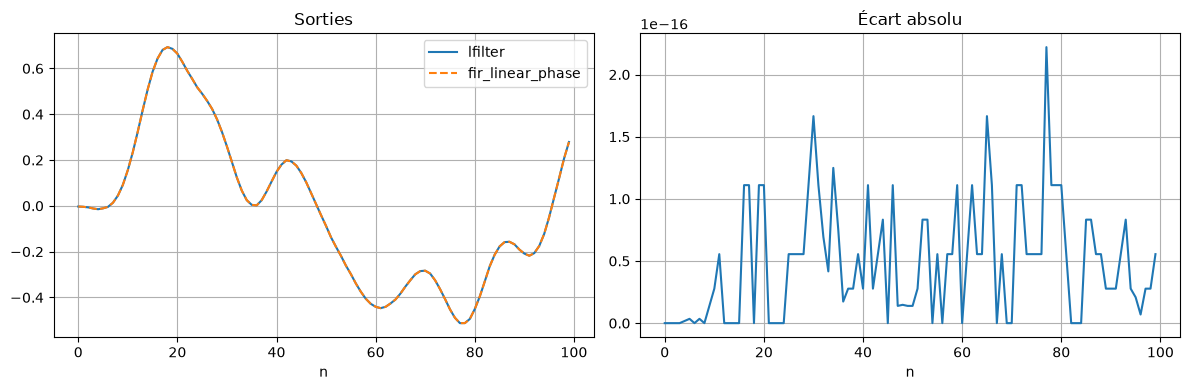

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def fir_linear_phase(x, b):
    """RIF à phase linéaire"""
    M = len(b)

    if M % 2 == 0:
        raise ValueError("La longueur doit être impaire")

    if not np.allclose(b, b[::-1]):
        raise ValueError("Les coefficients doivent être symétriques")

    L = (M - 1) // 2
    xp = np.concatenate([np.zeros(M - 1), x])
    y = np.zeros(len(x))

    for n in range(len(x)):
        f = xp[n:n + M][::-1]
        y[n] = b[L] * f[L] + np.sum(
            b[:L] * (f[:L] + f[M-1:L:-1])
        )

    return y


# Test avec un filtre de longueur 31
b = signal.firwin(31, 0.1)

np.random.seed(0)
x = np.random.randn(100)

y_sym = fir_linear_phase(x, b)
y_ref = signal.lfilter(b, 1, x)

print("Erreur max :", np.max(np.abs(y_sym - y_ref)))

print(
    "Multiplications / échantillon : direct =",
    len(b),
    "| symétrique =",
    (len(b) + 1) // 2
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(y_ref, label='lfilter')
plt.plot(y_sym, '--', label='fir_linear_phase')
plt.title('Sorties')
plt.xlabel('n')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(np.abs(y_sym - y_ref))
plt.title("Écart absolu")
plt.xlabel('n')
plt.grid()

plt.tight_layout()
plt.show()

## Exercice 2 – Filtre RII en cascade vs directe

1. Concevoir un filtre RII elliptique passe-bas avec les spécifications suivantes :
   - Fréquence de coupure 200 Hz, fs=1000 Hz.
   - Atténuation de 60 dB dans la bande stop à partir de 250 Hz.
   - Ondulation en bande passante : 0.5 dB.
2. Obtenir la forme en cascade (sos) et la forme directe.
3. Comparer les réponses en gain et en phase des deux formes.
4. Quantifier les coefficients sur 12 bits et observer l'impact sur la stabilité pour les deux structures.

**Code** :

In [ ]:
# Conception du filtre elliptique
# À compléter
# b, a = signal.ellip(..., ...)
# sos = signal.tf2sos(b, a)
# puis quantifier et comparer

Correction exercice 2

1. `ellipord` donne l'ordre minimal pour : passe-bas, $f_p = 200$ Hz, ondulation 0,5 dB, $f_s$ d'arrêt = 250 Hz, atténuation 60 dB.
2. Forme directe : $(b, a)$ avec `ellip`. Forme cascade : `tf2sos(b, a)` (sections de second ordre).
3. On compare les réponses en gain et en phase.
4. **Quantification** : on arrondit chaque jeu de coefficients à $n$ bits, avec un facteur d'échelle en puissance de 2 choisi selon le plus grand coefficient (1 bit de signe, le reste en partie entière et fractionnaire). En forme directe, on quantifie les vecteurs `b` et `a` ; en cascade, les coefficients de **chaque section**.

Ordre elliptique : 7 (fc = 200 Hz)
Nombre de sections biquad : 4
Écart max de gain directe/cascade (dB) : 4.5133674575481564e-11
Écart max de phase (rad) : 1.1088463480746213e-11


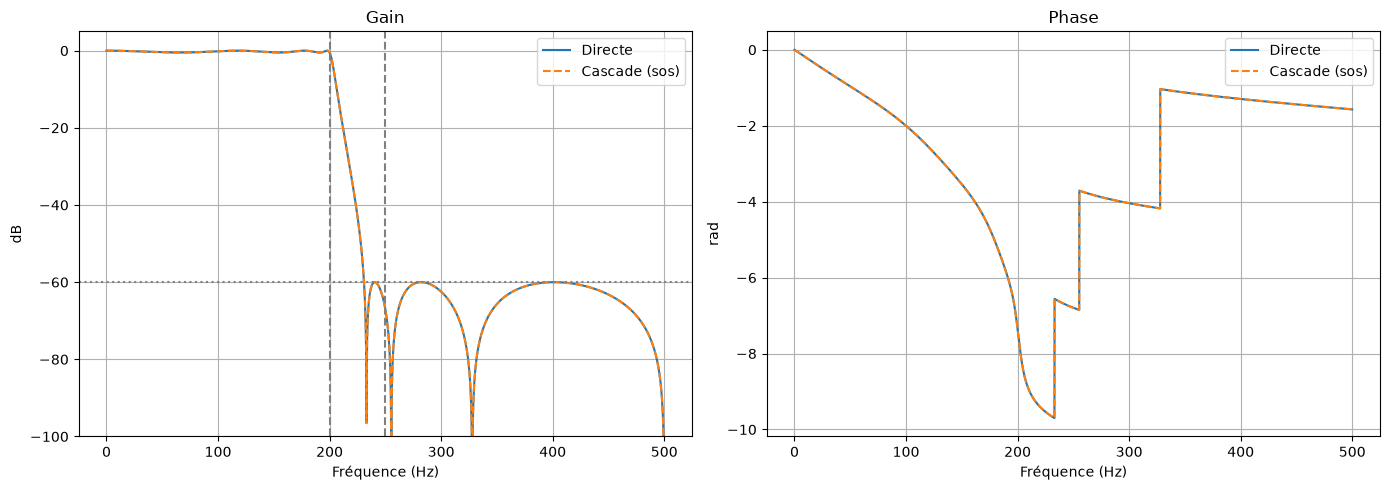

bits | directe |p|max  stable   ondul. bp (dB) | cascade |p|max  stable   ondul. bp (dB)
  16 |         0.9711    True [ -0.52, 0.08] |         0.9710    True [ -0.50, 0.00]
  12 |         0.9685    True [ -1.91, 0.19] |         0.9710    True [ -0.51, 0.01]
  10 |         0.9665    True [ -2.18, 6.65] |         0.9713    True [ -0.62, 0.02]
   9 |         1.0104   False [ -9.07, 2.02] |         0.9703    True [ -0.66, 0.04]
   8 |         1.0032   False [-16.27,45.71] |         0.9723    True [ -0.66, 0.49]


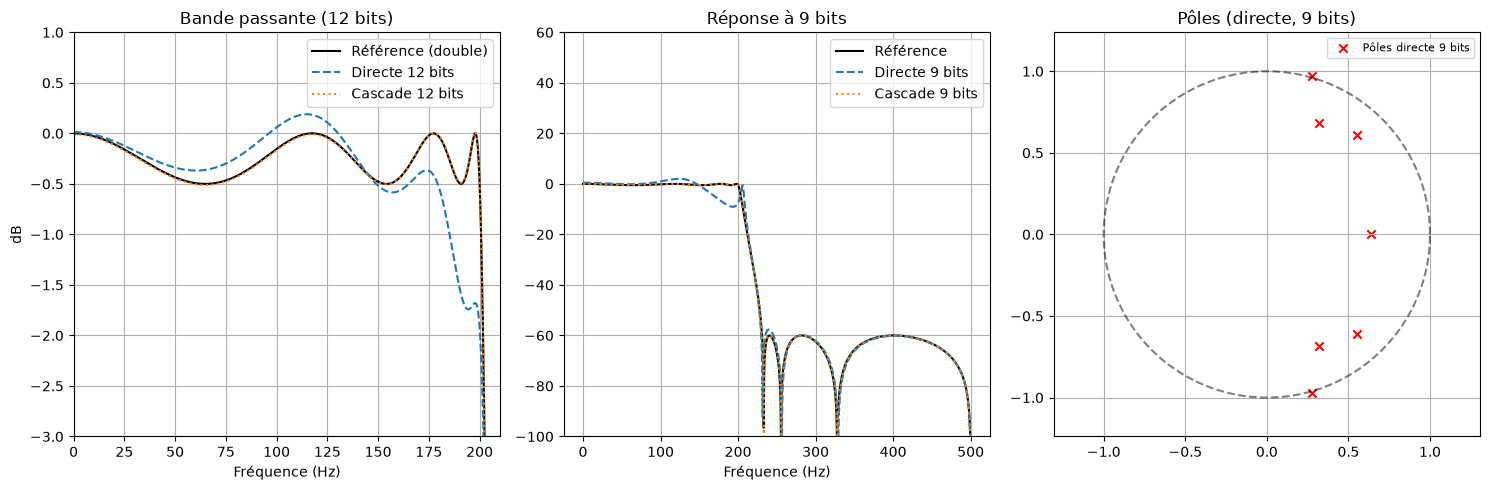

In [3]:
import warnings; warnings.filterwarnings('ignore')   # évite des avertissements scipy sur les filtres instables

fs = 1000
f_pass, f_stop = 200, 250
rp, rs = 0.5, 60

# 1. Conception
ordre, wn = signal.ellipord(f_pass, f_stop, rp, rs, fs=fs)
b_d, a_d = signal.ellip(ordre, rp, rs, wn, btype='low', fs=fs)
print(f"Ordre elliptique : {ordre} (fc = {wn:.0f} Hz)")

# 2. Forme cascade
sos = signal.tf2sos(b_d, a_d)
print(f"Nombre de sections biquad : {len(sos)}")

# 3. Comparaison gain / phase (précision double)
w, H_d = signal.freqz(b_d, a_d, worN=4096, fs=fs)
_, H_c = signal.sosfreqz(sos, worN=4096, fs=fs)
dB = lambda H: 20*np.log10(np.abs(H) + 1e-12)
print("Écart max de gain directe/cascade (dB) :", np.max(np.abs(dB(H_d) - dB(H_c))))
print("Écart max de phase (rad) :", np.max(np.abs(np.angle(H_d) - np.angle(H_c))))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(w, dB(H_d), label='Directe'); plt.plot(w, dB(H_c), '--', label='Cascade (sos)')
plt.axvline(f_pass, color='gray', linestyle='--'); plt.axvline(f_stop, color='gray', linestyle='--')
plt.axhline(-rs, color='gray', linestyle=':')
plt.title('Gain'); plt.xlabel('Fréquence (Hz)'); plt.ylabel('dB')
plt.ylim(-100, 5); plt.legend(); plt.grid()
plt.subplot(1, 2, 2)
plt.plot(w, np.unwrap(np.angle(H_d)), label='Directe')
plt.plot(w, np.unwrap(np.angle(H_c)), '--', label='Cascade (sos)')
plt.title('Phase'); plt.xlabel('Fréquence (Hz)'); plt.ylabel('rad'); plt.legend(); plt.grid()
plt.tight_layout(); plt.show()

# 4. Quantification
def quantize(c, n_bits):
    """Quantifie c sur n_bits (1 bit de signe) avec échelle en puissance de 2."""
    c = np.asarray(c, dtype=float)
    m = np.max(np.abs(c))
    if m == 0:
        return c
    int_bits = int(np.ceil(np.log2(m)))            # peut être négatif si |c| < 1
    step = 2.0 ** (int_bits - (n_bits - 1))        # pas de quantification
    return np.round(c / step) * step

def quantize_sos(sos, n_bits):
    s = sos.copy()
    for i in range(len(s)):
        s[i, :3] = quantize(s[i, :3], n_bits)      # b0 b1 b2
        s[i, 4:] = quantize(s[i, 4:], n_bits)      # a1 a2  (a0 = 1 reste exact)
    return s

print(f"{'bits':>4} | {'directe |p|max':>14} {'stable':>7} {'ondul. bp (dB)':>16} | "
      f"{'cascade |p|max':>14} {'stable':>7} {'ondul. bp (dB)':>16}")
res = {}
for nb in (16, 12, 10, 9, 8):
    aq, bq = quantize(a_d, nb), quantize(b_d, nb)
    p_d = np.roots(aq)                              # pôles de la forme directe
    sos_q = quantize_sos(sos, nb)
    _, p_c, _ = signal.sos2zpk(sos_q)               # pôles de la cascade
    _, Hd_q = signal.freqz(bq, aq, worN=4096, fs=fs)
    _, Hc_q = signal.sosfreqz(sos_q, worN=4096, fs=fs)
    r_d = dB(Hd_q[w <= f_pass]); r_c = dB(Hc_q[w <= f_pass])
    res[nb] = (Hd_q, Hc_q, p_d)
    print(f"{nb:4d} | {np.abs(p_d).max():14.4f} {str(np.all(np.abs(p_d)<1)):>7} "
          f"[{r_d.min():6.2f},{r_d.max():5.2f}] | "
          f"{np.abs(p_c).max():14.4f} {str(np.all(np.abs(p_c)<1)):>7} "
          f"[{r_c.min():6.2f},{r_c.max():5.2f}]")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(w, dB(H_d), 'k', label='Référence (double)')
plt.plot(w, dB(res[12][0]), '--', label='Directe 12 bits')
plt.plot(w, dB(res[12][1]), ':', label='Cascade 12 bits')
plt.xlim(0, 210); plt.ylim(-3, 1); plt.title('Bande passante (12 bits)')
plt.xlabel('Fréquence (Hz)'); plt.ylabel('dB'); plt.legend(); plt.grid()

plt.subplot(1, 3, 2)
plt.plot(w, dB(H_d), 'k', label='Référence')
plt.plot(w, dB(res[9][0]), '--', label='Directe 9 bits')
plt.plot(w, dB(res[9][1]), ':', label='Cascade 9 bits')
plt.ylim(-100, 60); plt.title('Réponse à 9 bits')
plt.xlabel('Fréquence (Hz)'); plt.legend(); plt.grid()

plt.subplot(1, 3, 3)
th = np.linspace(0, 2*np.pi, 300)
plt.plot(np.cos(th), np.sin(th), 'k--', alpha=0.5)
p9 = res[9][2]
plt.scatter(p9.real, p9.imag, marker='x', color='r', label='Pôles directe 9 bits')
plt.axis('equal'); plt.title('Pôles (directe, 9 bits)'); plt.legend(fontsize=8); plt.grid()
plt.tight_layout(); plt.show()

## Exercice 3 – Analyse du retard de groupe d'un filtre RIF et RII

1. Concevoir un filtre RIF passe-bas de type window (Hamming) avec fc=150 Hz, fs=1000 Hz, ordre 50.
2. Concevoir un filtre RII Butterworth d'ordre 6 avec les mêmes spécifications.
3. Tracer le retard de groupe des deux filtres sur la bande passante.
4. Commenter la distorsion de phase introduite par chaque filtre.

**Code** :

In [ ]:
# À compléter
# Utiliser scipy.signal.group_delay

Correction exercice 3

- RIF Hamming, ordre 50 → **51 coefficients**, $f_c = 150$ Hz. Phase linéaire : retard de groupe constant $(N-1)/2 = 25$ échantillons.
- RII Butterworth d'ordre 6, $f_c = 150$ Hz, même $f_s$.
- Retard de groupe : $\tau_g(\omega) = -\dfrac{d\,\arg H}{d\omega}$, calculé avec `signal.group_delay` sur la bande passante (0 – 150 Hz).

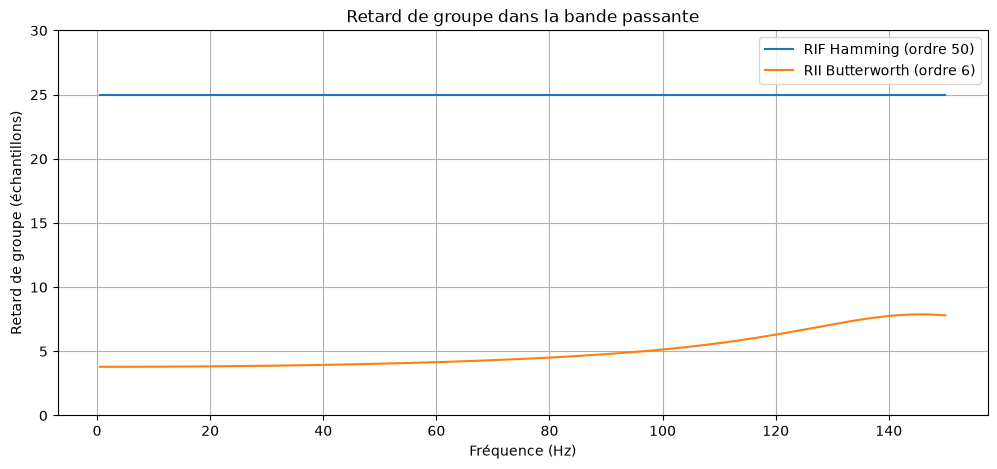

RIF : retard constant = 25.00 échantillons = 25.0 ms
RII : retard de 3.79 à 7.88 échantillons (variation = 4.09 échantillons = 4.1 ms)


In [4]:
fs = 1000
fc = 150

# 1. RIF Hamming, ordre 50 (51 coefficients)
b_f = signal.firwin(51, fc, fs=fs, window='hamming')
# 2. RII Butterworth ordre 6
b_i, a_i = signal.butter(6, fc, fs=fs, btype='low')

# 3. Retard de groupe sur la bande passante
f_bp = np.linspace(0.5, fc, 300)
_, gd_fir = signal.group_delay((b_f, 1), w=f_bp, fs=fs)
_, gd_iir = signal.group_delay((b_i, a_i), w=f_bp, fs=fs)

plt.figure(figsize=(12, 5))
plt.plot(f_bp, gd_fir, label='RIF Hamming (ordre 50)')
plt.plot(f_bp, gd_iir, label='RII Butterworth (ordre 6)')
plt.xlabel('Fréquence (Hz)'); plt.ylabel('Retard de groupe (échantillons)')
plt.title('Retard de groupe dans la bande passante')
plt.ylim(0, 30); plt.legend(); plt.grid()
plt.show()

print(f"RIF : retard constant = {gd_fir.mean():.2f} échantillons = {gd_fir.mean()/fs*1000:.1f} ms")
print(f"RII : retard de {gd_iir.min():.2f} à {gd_iir.max():.2f} échantillons "
      f"(variation = {gd_iir.max()-gd_iir.min():.2f} échantillons = "
      f"{(gd_iir.max()-gd_iir.min())/fs*1000:.1f} ms)")

## Exercice 4 – Effet du nombre de bits sur la réponse d'un filtre RII

Pour un filtre RII passe-bande (Butterworth ordre 4, bande 100-200 Hz, fs=1000 Hz) :
1. Quantifier les coefficients avec différentes résolutions (8, 10, 12, 16 bits).
2. Pour chaque résolution, tracer la réponse en gain et repérer les dégradations.
3. Observer le déplacement des pôles et déterminer la résolution minimale pour garantir la stabilité.

**Code** :

In [ ]:
# À compléter
# Générer les coefficients quantifiés pour différentes résolutions
# Tracer les réponses et les pôles

Correction exercice 4

Butterworth passe-bande d'ordre 4 (bande 100–200 Hz, $f_s = 1000$ Hz) : le filtre final est d'ordre **8** (9 coefficients dans `a`).
On quantifie $(b, a)$ en forme directe sur 8, 10, 12 et 16 bits, avec la fonction `quantize` définie à l'exercice 2. On trace les réponses en gain et le déplacement des pôles par rapport à la référence.
Pour la résolution minimale, on balaie de 6 à 20 bits et on cherche la plus petite valeur à partir de laquelle le filtre reste stable. On compare avec la forme cascade.

 8 bits : |p|max = 1.1945 -> stable = False | écart max de gain (60-300 Hz) = 10.70 dB
10 bits : |p|max = 1.0096 -> stable = False | écart max de gain (60-300 Hz) = 16.31 dB
12 bits : |p|max = 0.9062 -> stable = True | écart max de gain (60-300 Hz) = 2.62 dB
16 bits : |p|max = 0.9147 -> stable = True | écart max de gain (60-300 Hz) = 0.04 dB


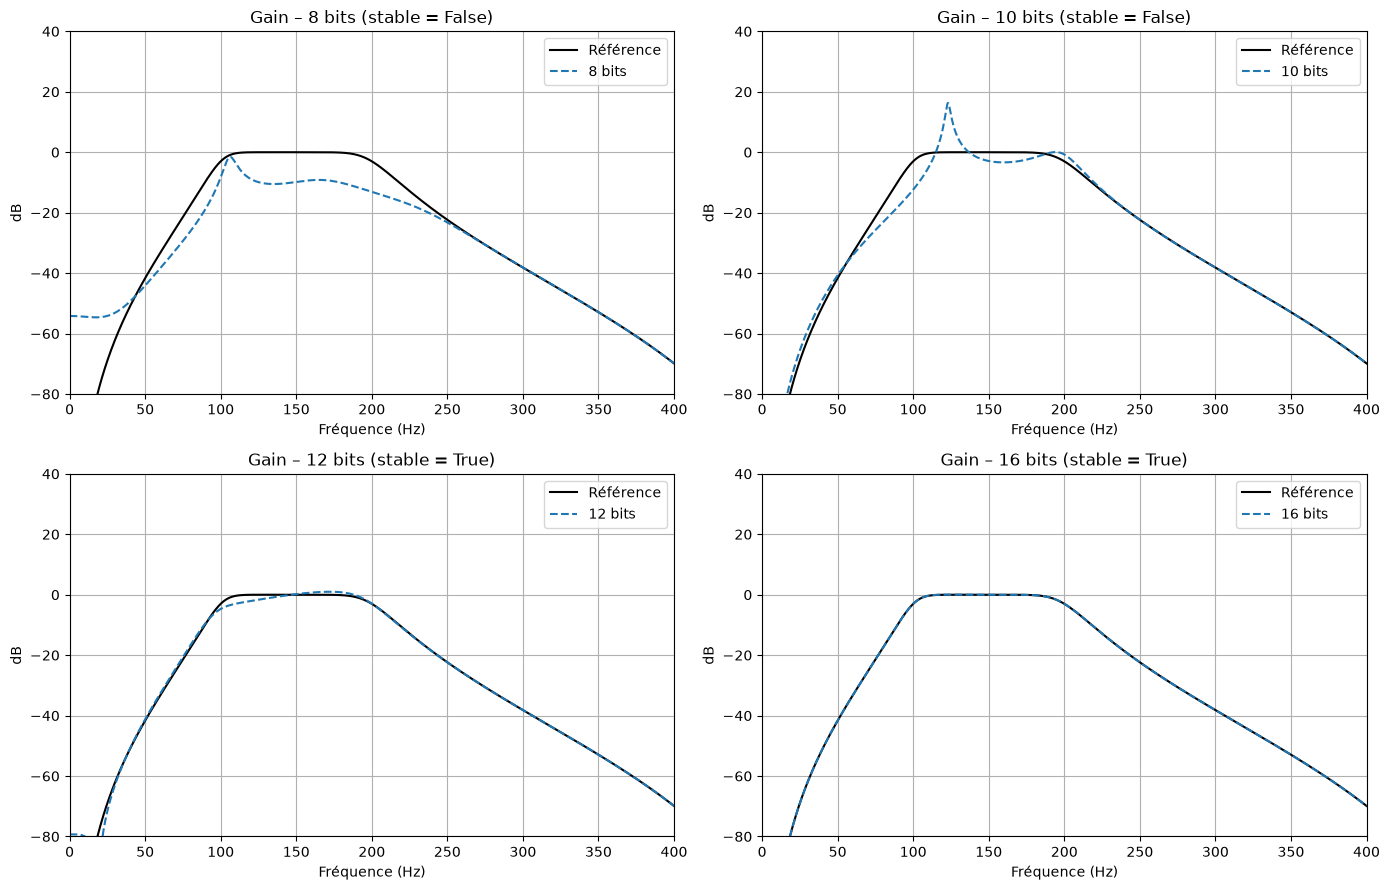

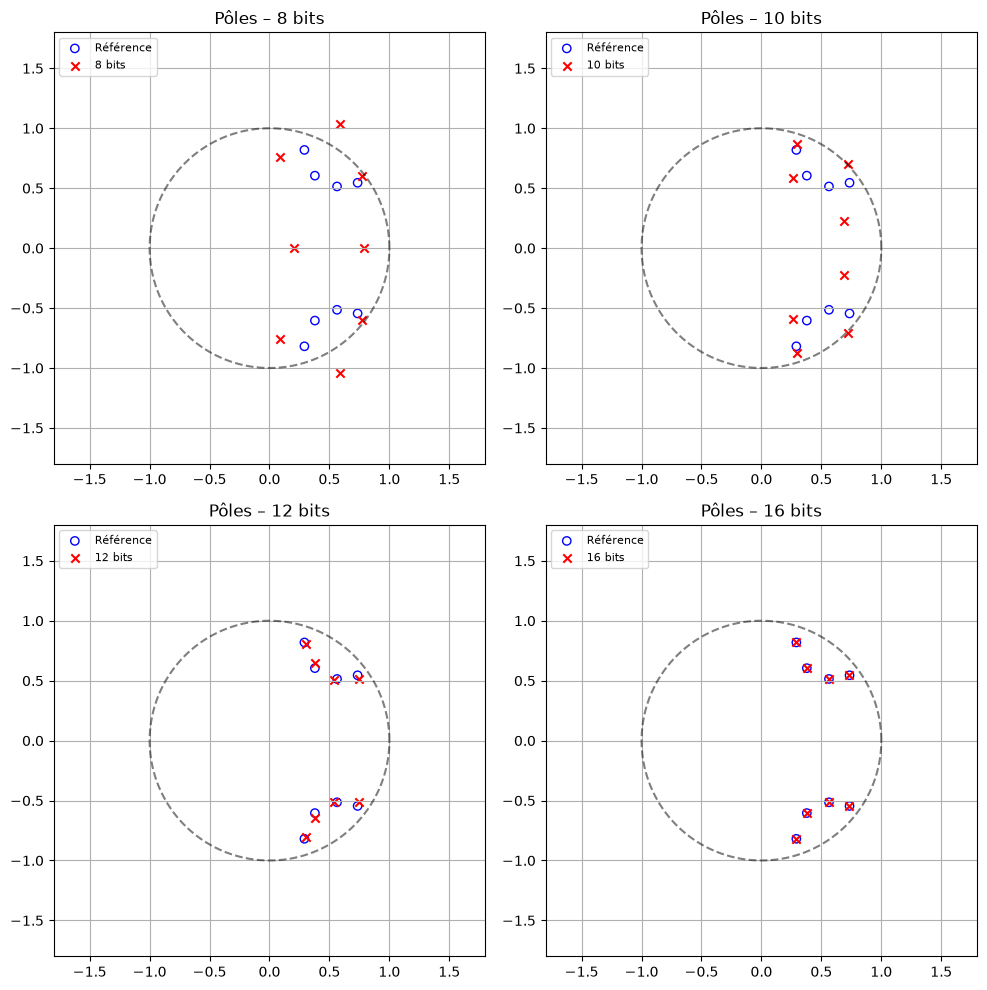

Résolution minimale pour la stabilité – forme directe : 11 bits
Résolution minimale pour la stabilité – cascade       : 6 bits (plage testée 6-20)


In [5]:
# (utilise les fonctions quantize et quantize_sos de l'exercice 2)
fs = 1000
b_bp, a_bp = signal.butter(4, [100, 200], btype='bandpass', fs=fs)
w, H_ref = signal.freqz(b_bp, a_bp, worN=4096, fs=fs)
dB = lambda H: 20*np.log10(np.abs(H) + 1e-12)
th = np.linspace(0, 2*np.pi, 300)
p_ref = np.roots(a_bp)

fig1, ax1 = plt.subplots(2, 2, figsize=(14, 9))     # réponses en gain
fig2, ax2 = plt.subplots(2, 2, figsize=(10, 10))    # pôles
for k, nb in enumerate([8, 10, 12, 16]):
    bq, aq = quantize(b_bp, nb), quantize(a_bp, nb)
    poles_q = np.roots(aq)
    _, Hq = signal.freqz(bq, aq, worN=4096, fs=fs)
    stable = np.all(np.abs(poles_q) < 1)
    err = np.max(np.abs(dB(Hq) - dB(H_ref))[(w >= 60) & (w <= 300)])
    print(f"{nb:2d} bits : |p|max = {np.abs(poles_q).max():.4f} -> stable = {stable} "
          f"| écart max de gain (60-300 Hz) = {err:.2f} dB")

    ax = ax1[k//2, k%2]
    ax.plot(w, dB(H_ref), 'k', label='Référence'); ax.plot(w, dB(Hq), '--', label=f'{nb} bits')
    ax.set_xlim(0, 400); ax.set_ylim(-80, 40)
    ax.set_title(f'Gain – {nb} bits (stable = {stable})')
    ax.set_xlabel('Fréquence (Hz)'); ax.set_ylabel('dB'); ax.legend(); ax.grid()

    ax = ax2[k//2, k%2]
    ax.plot(np.cos(th), np.sin(th), 'k--', alpha=0.5)
    ax.scatter(p_ref.real, p_ref.imag, marker='o', facecolors='none', edgecolors='b', label='Référence')
    ax.scatter(poles_q.real, poles_q.imag, marker='x', color='r', label=f'{nb} bits')
    ax.set_aspect('equal'); ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8)
    ax.set_title(f'Pôles – {nb} bits'); ax.legend(fontsize=8, loc='upper left'); ax.grid()
fig1.tight_layout(); fig2.tight_layout(); plt.show()

# Résolution minimale pour la stabilité : directe vs cascade
sos_bp = signal.butter(4, [100, 200], btype='bandpass', fs=fs, output='sos')
stable_ba, stable_sos = {}, {}
for nb in range(6, 21):
    stable_ba[nb] = np.all(np.abs(np.roots(quantize(a_bp, nb))) < 1)
    _, p_c, _ = signal.sos2zpk(quantize_sos(sos_bp, nb))
    stable_sos[nb] = np.all(np.abs(p_c) < 1)

def min_bits(d):
    """Plus petit nb tel que le filtre est stable pour tout nb' >= nb."""
    for nb in range(6, 21):
        if all(d[m] for m in range(nb, 21)):
            return nb

print("Résolution minimale pour la stabilité – forme directe :", min_bits(stable_ba), "bits")
print("Résolution minimale pour la stabilité – cascade       :", min_bits(stable_sos), "bits (plage testée 6-20)")

## Exercice 5 – Mise en œuvre d'un filtre adaptatif simple (LMS) – Introduction

Un filtre adaptatif permet d'ajuster ses coefficients pour minimiser une erreur. Implémenter un filtre RIF adaptatif utilisant l'algorithme LMS (Least Mean Squares) pour annuler un écho. On donne un signal désiré $d[n]$ et un signal d'entrée $x[n]$ corrélé avec l'écho.

1. Générer un signal $x[n]$ aléatoire.
2. Créer un signal écho : $y[n] = 0.8 x[n-10] + bruit$.
3. Utiliser un filtre RIF de longueur 20 pour estimer la réponse de l'écho.
4. Appliquer l'algorithme LMS (pas = 0.01) pour mettre à jour les coefficients.
5. Afficher l'erreur en fonction des itérations et les coefficients convergés.

**Code** :

In [ ]:
# Implémentation LMS
def lms_filter(x, d, M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N)
    for n in range(M, N):
        x_n = x[n-M:n][::-1]  # inversion pour convolution
        y[n] = np.dot(w, x_n)
        e[n] = d[n] - y[n]
        w = w + mu * e[n] * x_n
    return y, e, w

# Test
# Génération des signaux
# x = np.random.randn(500)
# d = ... (signal désiré)
# mu = 0.01
# y, e, w = lms_filter(x, d, 20, mu)
# Tracer l'erreur


Correction exercice 5

**Principe** : le filtre RIF adaptatif de coefficients $\mathbf{w}$ (longueur $M = 20$) estime l'écho $\hat d[n] = \mathbf{w}^T\mathbf{x}_n$. L'erreur est $e[n] = d[n] - \hat d[n]$ et LMS met à jour
$$ \mathbf{w} \leftarrow \mathbf{w} + \mu\, e[n]\, \mathbf{x}_n, \qquad \mathbf{x}_n = [x[n], x[n-1], \dots, x[n-M+1]]^T $$

**Convention** : ici le vecteur $\mathbf{x}_n$ **contient l'échantillon courant** $x[n]$ ; ainsi le coefficient $w[k]$ correspond directement au retard $k$. L'écho $0{,}8\,x[n-10]$ doit donc donner $w[10] \approx 0{,}8$ et les autres coefficients ≈ 0.

**Condition de convergence** : $0 < \mu < \dfrac{2}{M\,\sigma_x^2} = 0{,}1$. Avec $\mu = 0{,}01$, c'est largement vérifié.

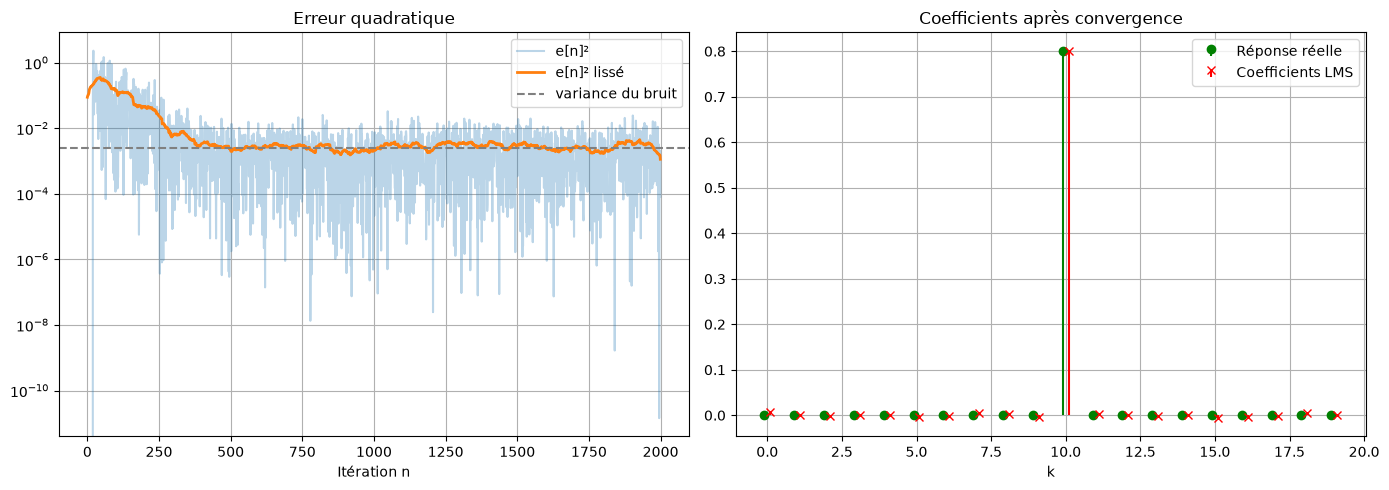

w[10] = 0.8012 (attendu 0.8) ; |w| max des autres = 0.0069
MSE début (n<200) = 0.1812 | MSE fin (300 derniers) = 0.00281 | variance bruit = 0.00250


In [6]:
def lms_filter(x, d, M, mu):
    N = len(x)
    w = np.zeros(M)
    y = np.zeros(N)
    e = np.zeros(N)
    for n in range(M - 1, N):
        x_n = x[n - M + 1:n + 1][::-1]   # [x[n], x[n-1], ..., x[n-M+1]]
        y[n] = np.dot(w, x_n)            # estimation de l'écho
        e[n] = d[n] - y[n]               # erreur
        w = w + mu * e[n] * x_n          # mise à jour LMS
    return y, e, w

# 1. Signal d'entrée aléatoire
np.random.seed(1)
N, M, mu, delai = 2000, 20, 0.01, 10
x = np.random.randn(N)

# 2. Écho : d[n] = 0,8 x[n-10] + bruit
bruit = 0.05 * np.random.randn(N)
d = np.zeros(N)
d[delai:] = 0.8 * x[:-delai]
d += bruit

# 3-4. Filtre RIF adaptatif de longueur 20, LMS (mu = 0,01)
y, e, w_lms = lms_filter(x, d, M, mu)

# 5. Erreur en fonction des itérations + coefficients convergés
w_true = np.zeros(M); w_true[delai] = 0.8
e2 = e**2
lisse = np.convolve(e2, np.ones(50)/50, mode='same')

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.semilogy(e2, alpha=0.3, label='e[n]²')
plt.semilogy(lisse, linewidth=2, label='e[n]² lissé')
plt.axhline(0.05**2, color='gray', linestyle='--', label='variance du bruit')
plt.title("Erreur quadratique"); plt.xlabel('Itération n'); plt.legend(); plt.grid()

plt.subplot(1, 2, 2)
plt.stem(np.arange(M) - 0.1, w_true, linefmt='g-', markerfmt='go', basefmt=' ', label='Réponse réelle')
plt.stem(np.arange(M) + 0.1, w_lms, linefmt='r-', markerfmt='rx', basefmt=' ', label='Coefficients LMS')
plt.title('Coefficients après convergence'); plt.xlabel('k'); plt.legend(); plt.grid()
plt.tight_layout(); plt.show()

print(f"w[10] = {w_lms[delai]:.4f} (attendu 0.8) ; |w| max des autres = "
      f"{np.max(np.abs(np.delete(w_lms, delai))):.4f}")
print(f"MSE début (n<200) = {np.mean(e2[M:200]):.4f} | "
      f"MSE fin (300 derniers) = {np.mean(e2[-300:]):.5f} | variance bruit = {0.05**2:.5f}")

# 5. Livrable Semaine 10

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---